# 012 LSTM 图像字幕：题目要求

**需要完成：** 实现 LSTM 门控、单步/序列前后向；固定参考和数值梯度检查；50 字幕小样本训练 50 轮；生成字幕并按原题 BLEU-1 评估。

**实验范围与验收：** 新增完整数据 GPU 等价训练共 20 轮。固定 1000 条验证字幕的平均单句 BLEU-1 单独报告；0.3 是原题加分参考，不等同于 corpus BLEU-4。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。

## 读代码前先看模型：长短期记忆网络

LSTM 同时传递细胞状态和隐藏状态。遗忘门控制旧记忆保留多少，输入门控制写入多少候选内容，输出门决定当前向外暴露多少记忆。

![长短期记忆网络的数据流](../assets/model_flow/012_LSTM_Captioning.svg)

**从定义推到实现。**

$$
c_t=f_t c_{t-1}+i_t g_t,\quad h_t=o_t\tanh(c_t)
$$

反向时先把未来直接传来的 dc 与 dh·o·(1−tanh²c) 相加。这个总量乘 f 得到传往旧记忆的梯度，乘旧记忆得到遗忘门梯度，再通过 sigmoid 导数。遗漏其中任何一路都会使整段梯度错误。

**库在这里解决什么问题？** 手写代码门序为 i/f/o/g，PyTorch 为 i/f/g/o。即使矩阵尺寸一致也必须重排门和梯度，再比较损失、解码以及参数更新。

**代入具体数值看公式。** 若遗忘门接近 1、输入门接近 0，则细胞状态近似复制旧记忆。即使输出门暂时关闭，记忆仍可传向下一步；这解释了为什么反向传播必须保留独立的 dc 路径。

## 从问题推到实现：从两个状态的微分推回四个门

**第 1 步。** 一次仿射得到 z 并按 i/f/o/g 分为四块。前三块经 sigmoid，候选 g 经 tanh。cₜ=f·cₜ₋₁+i·g，hₜ=o·tanh(cₜ)。

**第 2 步。** 先求合并后的细胞梯度 q=dc_future+dh·o·(1−tanh²cₜ)。于是 dc_prev=qf，di=qg，dg=qi，df=q·c_prev，do=dh·tanh(cₜ)。这些是对门输出的导数。

**第 3 步。** 还要乘门激活函数的局部导数：di·i(1−i)、df·f(1−f)、do·o(1−o)、dg·(1−g²)。按原门序拼为 dz，最后用 xᵀdz、h_prevᵀdz 得到两组权重梯度。

### 关键参数逐项读

- cell_type=lstm：启用 h、c 两条递推。
- Wx.shape=(W,4H)、Wh.shape=(H,4H)：末维同时包含四个门。
- b.shape=(4H,)：广播到全批次。
- batch_size=25：原小样本训练每批字幕数；完整训练为 100。
- length_alpha：束搜索对累计 log 概率的长度归一化系数。

### 库的整体职责与本题用法

| 库或项目包 | 整体职责 | 本题中的调用和目的 |
|---|---|---|
| `__future__` | 声明 Python 语言兼容语义，属于解释器支持的特殊导入。 | 保留代码所声明的 Python 语言语义，本身不执行数据变换。 |
| `cs231n` | 当前作业自己的本地 Python 包，封装教学数据、手写算子、模型与训练循环。 | `load_coco_data` 读取预处理字幕、词表、图片索引与视觉特征；`eval_numerical_gradient_array` 逐坐标扰动输入，把输出差与上游梯度相乘后求和，以检查链式法则；`sample_coco_minibatch` 先抽字幕行，再通过图片索引取相应特征与 URL；`decode_captions` 把词编号序列还原成文字，在 END 处停止显示 |
| `json` | 在基本 Python 数据结构和可阅读文本之间序列化、反序列化。 | 写出实测指标，或读回已训练模型的样例记录。 |
| `matplotlib` | Matplotlib 是绘图库，负责把数值映射成坐标、曲线、像素和颜色。 | `plt.plot` 把记录量按其顺序连成曲线，观察变化趋势；`plt.show` 将当前图提交给 notebook 显示 |
| `nltk` | 自然语言处理工具库，本题使用其中的文本评价算法。 | 用 sentence_bleu 比较预测与参考字幕的一元词重合。 |
| `numpy` | NumPy 是多维数组与数值计算库，提供广播、向量化、线性代数和随机采样。 | `np.random.seed` 设定 NumPy 的随机序列起点，便于重复同一初始化或梯度检查；`np.max` 沿指定轴得到最大数值，与 argmax 返回的位置索引区别开；`np.abs` 计算绝对值，使差异不因正负号相互抵消；`np.maximum` 逐位置取较大值，用于 ReLU 或 hinge 的截断 |
| `os` | Python 标准库的操作系统接口，管理路径、环境变量和文件操作。 | 提供运行环境接口；若当前单元只有 import，则仅注册模块。 |
| `pathlib` | Python 标准库的路径对象，用来表达目录关系和文件读写。 | 从当前作业目录定位项目根目录与结果文件。 |
| `random` | Python 标准库的伪随机数模块，与 NumPy 和 PyTorch 的随机状态分开。 | 固定 Python 的随机起点，或在图像优化中抽取平移量。 |
| `study_runtime` | 本项目的数据路径与实验记录辅助模块。 | `save_experiment` 保存已完成计算的模型与指标，避免把原始数据复制进检查点 |
| `sys` | Python 标准库的解释器接口，可配置模块搜索路径。 | 把项目根目录加入模块搜索路径，使本作业找到共享辅助代码。 |
| `threadpoolctl` | 控制底层数值库线程池的工具，可使计时实验的线程设置一致。 | `threadpool_limits` 限制底层数值线程，避免小矩阵计算受过多线程调度影响 |
| `time` | Python 标准库的计时模块，用于测量持续时间和记录时刻。 | 用于本题显式导入的接口。 |

## 读论文图：多个 LSTM 方框共享哪些量？

![Show and Tell 图 3](https://ar5iv.labs.arxiv.org/html/1411.4555/assets/unrolled_lstm.png)

Vinyals 等，*Show and Tell*，图 3，PDF 第 4 页。门控结构可结合[同文图 2，第 3 页](https://openaccess.thecvf.com/content_cvpr_2015/papers/Vinyals_Show_and_Tell_2015_CVPR_paper.pdf#page=3)阅读。[图 3 原页](https://openaccess.thecvf.com/content_cvpr_2015/papers/Vinyals_Show_and_Tell_2015_CVPR_paper.pdf#page=4)

沿时间轴读蓝色连接：每个方框是同一组参数在不同时间步的一次调用。前一步留下 h 和 c，当前步再读一个词向量。论文将视觉表示送入序列的方式与本题直接投影 h₀ 不同，二者共同体现了视觉信息对下一词分布的约束。

反向时，c 既通过 tanh 和输出门影响当前 h，又直接进入下一步的细胞状态。于是 dc 包含来自当前输出和来自未来细胞状态的两项。读 lstm_step_backward 时先找到合并它们的加法，再看如何乘 f、i、g 并按门序拼回仿射梯度。

# 图像标题与LSTMs
在前面的练习中，您实现了一个普通的RNN并将其应用于图像字幕。在这个笔记本中，您将实现LSTM更新规则并将其用于图像标题。

**本段解析**

**工作机制与执行链。** 这个单元初始化实验上下文。将当前作业的父目录加入 sys.path 后，Python 可以找到共享的 study_runtime；当前目录仍提供该 assignment 自己的 cs231n 包。NumPy 和标准库 random 分别设种子，threadpool_limits 设置 BLAS 的线程上限。下一单元才真正读取数据或实例化模型。

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

**第 1 块：顺着变量读**

本块实际导入：`os`、`sys`、`random`、`pathlib.Path`、`study_runtime.data_path`、`numpy`、`threadpoolctl.threadpool_limits`。各模块在本题中的职责见开头的库说明。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `threadpool_limits` | `limits=4` | 底层 BLAS 线程数上限，影响并行调度和计时。 |
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


**第 2 块｜准备 LSTM 与梯度工具**

**工作机制与执行链。** 相较普通 RNN，这里每步还要保存 c。导入的 LSTM 单步与序列函数承担门控计算，字幕数据和词表投影仍沿用同一接口。

导入 LSTM 单步/序列算子和与 RNN 共用的字幕模型、数据与 Solver。LSTM 增加细胞状态 c，门控计算需要同时跟踪 h 和 c 的前向及反向路径。

此处定义 `rel_error(x, y)`。函数体在调用时执行。

本块实际导入：`__future__.print_function`、`time`、`os`、`json`、`numpy`、`matplotlib.pyplot`、`cs231n.gradient_check.eval_numerical_gradient`、`cs231n.gradient_check.eval_numerical_gradient_array`、`cs231n.rnn_layers.*`、`cs231n.captioning_solver.CaptioningSolver`、`cs231n.classifiers.rnn.CaptioningRNN`、`cs231n.coco_utils.load_coco_data`、`cs231n.coco_utils.sample_coco_minibatch`、`cs231n.coco_utils.decode_captions`、`cs231n.image_utils.image_from_url`。各模块在本题中的职责见开头的库说明。

本块产出的变量接着用于：`rel_error` → 第 4 块。

In [2]:
from __future__ import print_function
import time, os, json
import numpy as np
import matplotlib.pyplot as plt

from cs231n.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from cs231n.rnn_layers import *
from cs231n.captioning_solver import CaptioningSolver
from cs231n.classifiers.rnn import CaptioningRNN
from cs231n.coco_utils import load_coco_data, sample_coco_minibatch, decode_captions
from cs231n.image_utils import image_from_url

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) 
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# IPython 加载 autoreload 扩展，使内核能够重新导入改动过的 Python 模块。
%load_ext autoreload
# 模式 2 在执行新单元前检查可重载模块。它不重新训练模型，也不清空已有变量。
%autoreload 2

def rel_error(x, y):
    """逐元素计算 |x−y| / max(1e−8, |x|+|y|)，返回其中最大值。分母很小时还应查看绝对误差。"""
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

# 加载MS-COCO数据
和之前的笔记本一样，我们将使用Microsoft COCO数据集进行字幕。

**第 3 块｜核对共享 COCO 数据**

**工作机制与执行链。** 视觉 PCA 特征仍为 512 维，字幕和图像通过索引关联。复用路径只改变数据位置，不改变训练与验证划分。

复用同一份 COCO 特征、字幕和词表，不重新下载。训练与验证图像索引分别指向各自特征矩阵，PCA 模式输出 512 维图像表示。

本块产出的变量接着用于：`data` → 第 9 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `load_coco_data` | `pca_features=True` | 是否读取课程 PCA 降维后的视觉特征。 |

**形状怎么核对。**

本次已执行单元打印：`train_captions <class 'numpy.ndarray'> (400135, 17) int32`；`train_image_idxs <class 'numpy.ndarray'> (400135,) int32`；`val_captions <class 'numpy.ndarray'> (195954, 17) int32`；`val_image_idxs <class 'numpy.ndarray'> (195954,) int32`；`train_features <class 'numpy.ndarray'> (82783, 512) float32`；`val_features <class 'numpy.ndarray'> (40504, 512) float32`；`train_urls <class 'numpy.ndarray'> (82783,) <U63`；`val_urls <class 'numpy.ndarray'> (40504,) <U63`。

**这里没有显式传入、但实际生效的默认参数。**

- `load_coco_data(..., base_dir=BASE_DIR)`：课程 COCO 文件所在目录，由共享路径配置解析。
- `load_coco_data(..., max_train=None)`：限制读取的训练字幕行数，不等于限制图像特征矩阵行数。

In [3]:
data = load_coco_data(pca_features=True)

for k, v in data.items():
    if type(v) == np.ndarray:
        print(k, type(v), v.shape, v.dtype)
    else:
        print(k, type(v), len(v))

train_captions <class 'numpy.ndarray'> (400135, 17) int32
train_image_idxs <class 'numpy.ndarray'> (400135,) int32
val_captions <class 'numpy.ndarray'> (195954, 17) int32
val_image_idxs <class 'numpy.ndarray'> (195954,) int32
train_features <class 'numpy.ndarray'> (82783, 512) float32
val_features <class 'numpy.ndarray'> (40504, 512) float32
idx_to_word <class 'list'> 1004
word_to_idx <class 'dict'> 1004
train_urls <class 'numpy.ndarray'> (82783,) <U63
val_urls <class 'numpy.ndarray'> (40504,) <U63


# LSTM
如果你读了最近的论文，你会发现很多人使用vanialla RNN的一个变种，叫做长短时记忆(LSTM) RNNs。由于重复矩阵乘法导致的梯度消失和爆炸，普通的rns很难在长序列上训练。LSTMs解决了这个问题，它用如下的门控机制替换了普通RNN的简单更新规则。

与香草RNN类似,每一步都会收到一个输入$x_t\in\mathbb{R}^D$和上一个隐藏状态$h_{t-1}\in\mathbb{R}^H$; LSTM 也维持一个$H$-维度*细胞状态*,所以我们也收到之前的细胞状态$c_{t-1}\in\mathbb{R}^H$。 LSTM 的可学习参数是* 输入到隐藏* 矩阵$W_x\in\mathbb{R}^{4H\times D}$,一个“隐藏到隐藏的”矩阵$W_h\in\mathbb{R}^{4H\times H}$和一个*bias 矢量*$b\in\mathbb{R}^{4H}$.

每一步,我们先计算一个* 激活矢量*$a\in\mathbb{R}^{4H}$ as $a=W_xx_t + W_hh_{t-1}+b$。然后,我们将它分为四个向量$a_i,a_f,a_o,a_g\in\mathbb{R}^H$ where $a_i$由第一个$H$要素$a$, $a_f$下一个$H$要素$a$等,然后我们计算输入门$g\in\mathbb{R}^H$,*忘了门*$f\in\mathbb{R}^H$,*输出门*$o\in\mathbb{R}^H$和*块输入*$g\in\mathbb{R}^H$ as

$$
\begin{align*}
i = \sigma(a_i) \hspace{2pc}
f = \sigma(a_f) \hspace{2pc}
o = \sigma(a_o) \hspace{2pc}
g = \tanh(a_g)
\end{align*}
$$

where $\sigma$是 sigmoid 函数,并且$\tanh$是双曲正切, 两者都是应用元素 。

最后我们计算下一个细胞状态$c_t$和下一个隐藏状态$h_t$ as

$$
c_{t} = f\odot c_{t-1} + i\odot g \hspace{4pc}
h_t = o\odot\tanh(c_t)
$$

where $\odot$是向量的元素化产物。

在笔记本的其余部分,我们将执行 LSTM 更新规则,并将其应用到图像字幕任务中.

在代码中,我们假设数据是分批存储的,以便$X_t \in \mathbb{R}^{N\times D}$,并将与* 已转换的* 参数版本合作:$W_x \in \mathbb{R}^{D \times 4H}$, $W_h \in \mathbb{R}^{H\times 4H}$这样就可以激活了$A \in \mathbb{R}^{N\times 4H}$可有效计算为:$A = X_t W_x + H_{t-1} W_h$

# LSTM: 单步前向
在文件“cs231n/rnn_layers.py”中的“lstm_step_forward”函数中为LSTM的单个时间步长实现前向传播。这应该类似于您在上面实现的' rnn_step_forward '函数，但是使用的是LSTM更新规则。
完成之后，运行以下代码来执行对实现的简单测试。您应该看到“1e-8”或以下的错误。

**第 4 块｜计算单步门与状态**

**工作机制与执行链。** 将仿射输出 N×4H 按列分成 i、f、o、g，分别计算门值；更新 c 后再更新 h。给定固定数组，应同时核对 next_c 和 next_h。

固定输入和前一时刻 h、c，按 i、f、o、g 的门顺序计算 sigmoid/sigmoid/sigmoid/tanh。先用 c_next=f·c_prev+i·g 更新记忆，再用 h_next=o·tanh(c_next) 输出隐藏状态，并对照参考。

- `np.linspace(-0.4, 1.2, num=N * D).reshape(N, D)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.linspace` | `num=4 * H` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |
| `lstm_step_forward` | `x=x` | (N,D) 当前词向量。 |
| `lstm_step_forward` | `prev_h=prev_h` | 上一时间步的隐藏状态。 |
| `lstm_step_forward` | `prev_c=prev_c` | 上一时间步的细胞状态。 |
| `lstm_step_forward` | `Wx=Wx` | (D,4H) 输入到四个门的矩阵。 |
| `lstm_step_forward` | `Wh=Wh` | (H,4H) 前一隐藏状态到四个门的矩阵。 |
| `lstm_step_forward` | `b=b` | (4H,) 四门偏置，列按 i/f/o/g 排列。 |
| `rel_error` | `x=expected_next_h` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=next_h` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=expected_next_c` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=next_c` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `np.linspace` | `num=N * D` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |
| `np.linspace` | `num=N * H` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |
| `np.linspace` | `num=4 * D * H` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |
| `np.linspace` | `num=4 * H * H` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |

**进入底层实现。**

- [`lstm_step_forward`](cs231n/rnn_layers.py#L171)：把线性输出分为 i/f/o/g 四块；前三块 sigmoid，候选记忆 tanh。通过 c_next=f*c_prev+i*g 和 h_next=o*tanh(c_next) 更新，缓存门值和状态供反向。


**形状怎么核对。**

本块显式设定：`N=3` 表示该批次的样本数；`D=4` 表示当前输入的特征宽度；词嵌入测试中指每个词的向量宽度；`H=5` 表示隐藏状态或隐藏层的宽度。

由构造或 reshape 的实参可直接读出：`x` → `(3, 4)`；`prev_h` → `(3, 5)`；`prev_c` → `(3, 5)`；`Wx` → `(4, 20)`；`Wh` → `(5, 20)`。

In [4]:
N, D, H = 3, 4, 5
x = np.linspace(-0.4, 1.2, num=N*D).reshape(N, D)
prev_h = np.linspace(-0.3, 0.7, num=N*H).reshape(N, H)
prev_c = np.linspace(-0.4, 0.9, num=N*H).reshape(N, H)
Wx = np.linspace(-2.1, 1.3, num=4*D*H).reshape(D, 4 * H)
Wh = np.linspace(-0.7, 2.2, num=4*H*H).reshape(H, 4 * H)
b = np.linspace(0.3, 0.7, num=4*H)

next_h, next_c, cache = lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)

expected_next_h = np.asarray([
    [ 0.24635157,  0.28610883,  0.32240467,  0.35525807,  0.38474904],
    [ 0.49223563,  0.55611431,  0.61507696,  0.66844003,  0.7159181 ],
    [ 0.56735664,  0.66310127,  0.74419266,  0.80889665,  0.858299  ]])
expected_next_c = np.asarray([
    [ 0.32986176,  0.39145139,  0.451556,    0.51014116,  0.56717407],
    [ 0.66382255,  0.76674007,  0.87195994,  0.97902709,  1.08751345],
    [ 0.74192008,  0.90592151,  1.07717006,  1.25120233,  1.42395676]])

print('next_h error: ', rel_error(expected_next_h, next_h))
print('next_c error: ', rel_error(expected_next_c, next_c))

next_h error:  5.7054131967097955e-09
next_c error:  5.8143123088804145e-09


# LSTM: 单步反向
在文件“cs231n/rnn_layers.py”中的函数“lstm_step_back”中为单个LSTM时间步长实现向后传递。完成后，运行以下命令对实现执行数值梯度检查。您应该看到“1e-6”或以下的错误。

**第 5 块｜检查两条状态梯度**

**工作机制与执行链。** 给定两个独立上游梯度 dnext_h 和 dnext_c。先合并细胞状态的两条导数，再分回各门，数值检查要覆盖 prev_c 和 prev_h。

同时给 dnext_h 和 dnext_c，检查所有六组输入/参数梯度。细胞状态的总梯度包含直接从未来传来的项和从 h_next 经 tanh 传来的项，遗漏其中一路会导致序列反向错误。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `lstm_step_forward` | `x=x` | (N,D) 当前词向量。 |
| `lstm_step_forward` | `prev_h=prev_h` | 上一时间步的隐藏状态。 |
| `lstm_step_forward` | `prev_c=prev_c` | 上一时间步的细胞状态。 |
| `lstm_step_forward` | `Wx=Wx` | (D,4H) 输入到四个门的矩阵。 |
| `lstm_step_forward` | `Wh=Wh` | (H,4H) 前一隐藏状态到四个门的矩阵。 |
| `lstm_step_forward` | `b=b` | (4H,) 四门偏置，列按 i/f/o/g 排列。 |
| `lstm_step_backward` | `dnext_h=dnext_h` | 当前单步输出 h 收到的梯度。 |
| `lstm_step_backward` | `dnext_c=dnext_c` | 当前单步输出 c 收到的梯度。 |
| `lstm_step_backward` | `cache=cache` | 前向留下的中间状态，反向按对应顺序读取。 |
| `rel_error` | `x=dx_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dx` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dh_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dh` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dc_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dc` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dWx_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dWx` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dWh_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dWh` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=db_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=db` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |

**进入底层实现。**

- [`lstm_step_forward`](cs231n/rnn_layers.py#L171)：把线性输出分为 i/f/o/g 四块；前三块 sigmoid，候选记忆 tanh。通过 c_next=f*c_prev+i*g 和 h_next=o*tanh(c_next) 更新，缓存门值和状态供反向。
- [`lstm_step_backward`](cs231n/rnn_layers.py#L199)：先汇合 h_next 和未来 c_next 对细胞状态的梯度，再分别回传 i/f/o/g。按与前向一致的门顺序拼接 dz，计算输入、前状态和权重梯度。


**形状怎么核对。**

本块显式设定：`N=4` 表示该批次的样本数；`D=5` 表示当前输入的特征宽度；词嵌入测试中指每个词的向量宽度；`H=6` 表示隐藏状态或隐藏层的宽度。

由构造或 reshape 的实参可直接读出：`x` → `(4, 5)`；`prev_h` → `(4, 6)`；`prev_c` → `(4, 6)`；`Wx` → `(5, 24)`；`Wh` → `(6, 24)`；`b` → `(24,)`。

In [5]:
np.random.seed(231)

N, D, H = 4, 5, 6
x = np.random.randn(N, D)
prev_h = np.random.randn(N, H)
prev_c = np.random.randn(N, H)
Wx = np.random.randn(D, 4 * H)
Wh = np.random.randn(H, 4 * H)
b = np.random.randn(4 * H)

next_h, next_c, cache = lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)

dnext_h = np.random.randn(*next_h.shape)
dnext_c = np.random.randn(*next_c.shape)

fx_h = lambda x: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]
fh_h = lambda h: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]
fc_h = lambda c: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]
fWx_h = lambda Wx: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]
fWh_h = lambda Wh: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]
fb_h = lambda b: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[0]

fx_c = lambda x: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]
fh_c = lambda h: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]
fc_c = lambda c: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]
fWx_c = lambda Wx: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]
fWh_c = lambda Wh: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]
fb_c = lambda b: lstm_step_forward(x, prev_h, prev_c, Wx, Wh, b)[1]

num_grad = eval_numerical_gradient_array

dx_num = num_grad(fx_h, x, dnext_h) + num_grad(fx_c, x, dnext_c)
dh_num = num_grad(fh_h, prev_h, dnext_h) + num_grad(fh_c, prev_h, dnext_c)
dc_num = num_grad(fc_h, prev_c, dnext_h) + num_grad(fc_c, prev_c, dnext_c)
dWx_num = num_grad(fWx_h, Wx, dnext_h) + num_grad(fWx_c, Wx, dnext_c)
dWh_num = num_grad(fWh_h, Wh, dnext_h) + num_grad(fWh_c, Wh, dnext_c)
db_num = num_grad(fb_h, b, dnext_h) + num_grad(fb_c, b, dnext_c)

dx, dh, dc, dWx, dWh, db = lstm_step_backward(dnext_h, dnext_c, cache)

print('dx error: ', rel_error(dx_num, dx))
print('dh error: ', rel_error(dh_num, dh))
print('dc error: ', rel_error(dc_num, dc))
print('dWx error: ', rel_error(dWx_num, dWx))
print('dWh error: ', rel_error(dWh_num, dWh))
print('db error: ', rel_error(db_num, db))

dx error:  5.833093013472354e-10
dh error:  3.4168728051126624e-10
dc error:  1.5221723979041107e-10
dWx error:  1.6933643922734908e-09
dWh error:  2.7311400266248628e-08
db error:  1.7349356733443412e-10


# LSTM: 前向
在函数' lstm_forward '在文件' cs231n/rnn_layers。实现' lstm_forward '函数，在整个数据timeseries上运行LSTM forward。
完成后，运行以下代码来检查实现。你应该会看到一个关于“1e-7”的错误。

**第 6 块｜验证完整序列前向**

**工作机制与执行链。** 以零细胞状态和给定 h0 逐步递推。输出中的第 t 项应只依赖当前及此前输入，不能读取未来词。

从 h0 和零细胞状态开始逐时刻执行 LSTM，保存每步门值和状态。固定序列输出用于检查门顺序、初始状态及时间递推是否正确。

- `np.linspace(-0.4, 0.6, num=N * T * D).reshape(N, T, D)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.linspace` | `num=4 * H` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |
| `lstm_forward` | `x=x` | (N,T,D) 整段输入词向量序列。 |
| `lstm_forward` | `h0=h0` | 图像投影或给定的初始隐藏状态。 |
| `lstm_forward` | `Wx=Wx` | (D,4H) 四门输入权重。 |
| `lstm_forward` | `Wh=Wh` | (H,4H) 四门循环权重。 |
| `lstm_forward` | `b=b` | 偏置，沿样本维广播。 |
| `rel_error` | `x=expected_h` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=h` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `np.linspace` | `num=N * T * D` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |
| `np.linspace` | `num=N * H` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |
| `np.linspace` | `num=4 * D * H` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |
| `np.linspace` | `num=4 * H * H` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |

**进入底层实现。**

- [`lstm_forward`](cs231n/rnn_layers.py#L235)：以 h0 和全零 c0 开始逐词更新 LSTM，保存每个时间步的 gate/cache。输出 (N,T,H) 隐藏序列，词表投影在外部统一执行。


**形状怎么核对。**

本块显式设定：`N=2` 表示该批次的样本数；`D=5` 表示当前输入的特征宽度；词嵌入测试中指每个词的向量宽度；`H=4` 表示隐藏状态或隐藏层的宽度；`T=3` 表示序列的时间步数。

由构造或 reshape 的实参可直接读出：`x` → `(2, 3, 5)`；`h0` → `(2, 4)`；`Wx` → `(5, 16)`；`Wh` → `(4, 16)`。

In [6]:
N, D, H, T = 2, 5, 4, 3
x = np.linspace(-0.4, 0.6, num=N*T*D).reshape(N, T, D)
h0 = np.linspace(-0.4, 0.8, num=N*H).reshape(N, H)
Wx = np.linspace(-0.2, 0.9, num=4*D*H).reshape(D, 4 * H)
Wh = np.linspace(-0.3, 0.6, num=4*H*H).reshape(H, 4 * H)
b = np.linspace(0.2, 0.7, num=4*H)

h, cache = lstm_forward(x, h0, Wx, Wh, b)

expected_h = np.asarray([
 [[ 0.01764008,  0.01823233,  0.01882671,  0.0194232 ],
  [ 0.11287491,  0.12146228,  0.13018446,  0.13902939],
  [ 0.31358768,  0.33338627,  0.35304453,  0.37250975]],
 [[ 0.45767879,  0.4761092,   0.4936887,   0.51041945],
  [ 0.6704845,   0.69350089,  0.71486014,  0.7346449 ],
  [ 0.81733511,  0.83677871,  0.85403753,  0.86935314]]])

print('h error: ', rel_error(expected_h, h))

h error:  8.610537442272635e-08


# LSTM: 反向
在文件“cs231n/rnn_layers.py”中的函数“lstm_back”中对整个数据timeseries执行LSTM的向后传递。完成后，运行以下命令对实现执行数值梯度检查。您应该看到“1e-7”或以下的错误。

**第 7 块｜验证完整序列反向**

**工作机制与执行链。** 逆序传递 dh 和 dc 两路状态，累加共享的 4H 宽权重梯度。若只沿 h 回传，单步某些矩阵可能正确但序列梯度会失败。

沿时间反向遍历 cache，分别累计隐藏状态和细胞状态的跨步梯度，再累加共享 Wx、Wh、b 梯度。数值检查覆盖输入序列、初始隐藏状态和三组参数。

本块实际导入：`cs231n.rnn_layers.lstm_forward`、`cs231n.rnn_layers.lstm_backward`。各模块在本题中的职责见开头的库说明。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `lstm_forward` | `x=x` | (N,T,D) 整段输入词向量序列。 |
| `lstm_forward` | `h0=h0` | 图像投影或给定的初始隐藏状态。 |
| `lstm_forward` | `Wx=Wx` | (D,4H) 四门输入权重。 |
| `lstm_forward` | `Wh=Wh` | (H,4H) 四门循环权重。 |
| `lstm_forward` | `b=b` | 偏置，沿样本维广播。 |
| `lstm_backward` | `dh=dout` | 各时间步隐藏状态收到的上游梯度。 |
| `lstm_backward` | `cache=cache` | 前向留下的中间状态，反向按对应顺序读取。 |
| `eval_numerical_gradient_array` | `x=x` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=h0` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=Wx` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=Wh` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=b` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `rel_error` | `x=dx_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dx` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dh0_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dh0` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dWx_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dWx` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dWh_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dWh` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=db_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=db` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |

**进入底层实现。**

- [`lstm_forward`](cs231n/rnn_layers.py#L235)：以 h0 和全零 c0 开始逐词更新 LSTM，保存每个时间步的 gate/cache。输出 (N,T,H) 隐藏序列，词表投影在外部统一执行。
- [`lstm_backward`](cs231n/rnn_layers.py#L265)：逆序传递隐藏与细胞两条状态梯度；共享 Wx、Wh、b 的导数对时间求和。返回 dx、dh0 和三组参数梯度，不能遗漏跨时间的 dnext_c。
- [`eval_numerical_gradient_array`](cs231n/gradient_check.py#L41)：当 f 返回数组时，用初始版本 df 加权输出差分，得到链式法则对应的标量方向导数。每次扰动后恢复 x，返回与 x 同形状的数值梯度。


**形状怎么核对。**

本块显式设定：`N=2` 表示该批次的样本数；`D=3` 表示当前输入的特征宽度；词嵌入测试中指每个词的向量宽度；`T=10` 表示序列的时间步数；`H=6` 表示隐藏状态或隐藏层的宽度。

由构造或 reshape 的实参可直接读出：`x` → `(2, 10, 3)`；`h0` → `(2, 6)`；`Wx` → `(3, 24)`；`Wh` → `(6, 24)`；`b` → `(24,)`。

**这里没有显式传入、但实际生效的默认参数。**

- `eval_numerical_gradient_array(..., h=1e-05)`：中心差分步长：太大可能跨越非光滑点，太小会放大浮点消去误差。

In [7]:
from cs231n.rnn_layers import lstm_forward, lstm_backward
np.random.seed(231)

N, D, T, H = 2, 3, 10, 6

x = np.random.randn(N, T, D)
h0 = np.random.randn(N, H)
Wx = np.random.randn(D, 4 * H)
Wh = np.random.randn(H, 4 * H)
b = np.random.randn(4 * H)

out, cache = lstm_forward(x, h0, Wx, Wh, b)

dout = np.random.randn(*out.shape)

dx, dh0, dWx, dWh, db = lstm_backward(dout, cache)

fx = lambda x: lstm_forward(x, h0, Wx, Wh, b)[0]
fh0 = lambda h0: lstm_forward(x, h0, Wx, Wh, b)[0]
fWx = lambda Wx: lstm_forward(x, h0, Wx, Wh, b)[0]
fWh = lambda Wh: lstm_forward(x, h0, Wx, Wh, b)[0]
fb = lambda b: lstm_forward(x, h0, Wx, Wh, b)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
dh0_num = eval_numerical_gradient_array(fh0, h0, dout)
dWx_num = eval_numerical_gradient_array(fWx, Wx, dout)
dWh_num = eval_numerical_gradient_array(fWh, Wh, dout)
db_num = eval_numerical_gradient_array(fb, b, dout)

print('dx error: ', rel_error(dx_num, dx))
print('dh0 error: ', rel_error(dh0_num, dh0))
print('dWx error: ', rel_error(dWx_num, dWx))
print('dWh error: ', rel_error(dWh_num, dWh))
print('db error: ', rel_error(db_num, db))

dx error:  7.1480958161034e-10
dh0 error:  2.382478067689529e-08
dWx error:  8.000901525591848e-10
dWh error:  6.064216037522062e-07
db error:  6.280897271009326e-10


# LSTM 标题模式
现在您已经实现了一个LSTM，更新文件' cs231n/classifiers/rnn '中的' CaptioningRNN '类的' loss '方法的实现。来处理“自我”的情况。cell_type’是‘lstm’。这应该需要添加少于10行的代码。
完成之后，运行以下代码检查实现。你会看到一个小于“1e-10”的差值。

**第 8 块｜核对 LSTM 字幕损失**

**工作机制与执行链。** 固定字幕、图像特征和模型权重，检查整网损失。与 RNN 版本相比，主要变化位于循环单元，而非词表投影和 mask 定义。

使用固定权重运行完整 LSTM 字幕模型，比较带 NULL mask 的时序损失与参考值。图像投影、词嵌入和词表投影与 RNN 共用，区别在循环状态更新公式。

- `np.linspace(-0.5, 1.7, num=N * D).reshape(N, D)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `CaptioningRNN` | `input_dim=D` | 输入特征宽度；卷积构造器中用三元组表示通道、高、宽。 |
| `CaptioningRNN` | `wordvec_dim=W` | 词表中每个词对应的嵌入向量长度。 |
| `CaptioningRNN` | `hidden_dim=H` | 隐藏层或循环状态的宽度，决定内部表示能容纳多少分量。 |
| `CaptioningRNN` | `cell_type='lstm'` | 选择普通 RNN 或 LSTM，决定时间步递推规则和门矩阵宽度。 |
| `CaptioningRNN` | `dtype=np.float64` | 数据类型；float64 用于检查微小差分，float32 常用于正式训练。 |
| `CaptioningRNN` | `word_to_idx=word_to_idx` | 词字符串到整数编号的映射。 |
| `np.linspace` | `num=N * D` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |
| `np.linspace` | `num=v.size` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |

**进入底层实现。**

- [`CaptioningRNN`](cs231n/classifiers/rnn.py#L9)：用图像特征预测字幕。投影层把特征映射为初始隐藏状态，词嵌入把整数词号变为向量，循环层按时间处理序列，词表投影给出下一词得分。可选择普通 RNN 或 LSTM。
- [`model.loss`](cs231n/classifiers/rnn.py#L62)：图像特征投影为 h0，captions[:, :-1] 沿时间轴去掉末词作为输入，captions[:, 1:] 去掉起始词作为预测目标；循环输出经词表投影计算带 NULL 掩码的损失，再逐层手写反向。


**形状怎么核对。**

本块显式设定：`N=10` 表示该批次的样本数；`D=20` 表示当前输入的特征宽度；词嵌入测试中指每个词的向量宽度；`W=30` 表示词嵌入的宽度；`H=40` 表示隐藏状态或隐藏层的宽度；`T=13` 表示序列的时间步数。

由构造或 reshape 的实参可直接读出：`features` → `(10, 20)`；`captions` → `(10, 13)`。

In [8]:
N, D, W, H = 10, 20, 30, 40
word_to_idx = {'<NULL>': 0, 'cat': 2, 'dog': 3}
V = len(word_to_idx)
T = 13

model = CaptioningRNN(word_to_idx,
          input_dim=D,
          wordvec_dim=W,
          hidden_dim=H,
          cell_type='lstm',
          dtype=np.float64)

for k, v in model.params.items():
  model.params[k] = np.linspace(-1.4, 1.3, num=v.size).reshape(*v.shape)

features = np.linspace(-0.5, 1.7, num=N*D).reshape(N, D)
captions = (np.arange(N * T) % V).reshape(N, T)

loss, grads = model.loss(features, captions)
expected_loss = 9.82445935443

print('loss: ', loss)
print('expected loss: ', expected_loss)
print('difference: ', abs(loss - expected_loss))

loss:  9.824459354432264
expected loss:  9.82445935443
difference:  2.2648549702353193e-12


# 过度适应 LSTM 字幕模型
运行下面的代码，在与前面的RNN相同的小数据集上对LSTM字幕模型进行过度拟合。损失应该小于0.5。

**第 9 块｜训练 LSTM 小样本模型**

**工作机制与执行链。** 用 50 条抽样字幕、每批 25 条、50 轮检查 LSTM 过拟合。观察损失下降后，还需要比较训练与验证生成句，不能只以记忆训练样本作为质量证据。

用同一原题 50 条字幕、50 轮训练预算检验 LSTM 是否能过拟合。模型、参数和优化器与 RNN 实验独立；输出训练损失曲线，随后再检查真实字幕生成。

前序输入：`data` 来自第 3 块。

本块产出的变量接着用于：`small_data` → 第 10 块，`small_lstm_model` → 第 10 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `load_coco_data` | `max_train=50` | 限制读取的训练字幕行数，不等于限制图像特征矩阵行数。 |
| `CaptioningRNN` | `cell_type='lstm'` | 选择普通 RNN 或 LSTM，决定时间步递推规则和门矩阵宽度。 |
| `CaptioningRNN` | `word_to_idx=data['word_to_idx']` | 词字符串到整数编号的映射。 |
| `CaptioningRNN` | `input_dim=data['train_features'].shape[1]` | 输入特征宽度；卷积构造器中用三元组表示通道、高、宽。 |
| `CaptioningRNN` | `hidden_dim=512` | 隐藏层或循环状态的宽度，决定内部表示能容纳多少分量。 |
| `CaptioningRNN` | `wordvec_dim=256` | 词表中每个词对应的嵌入向量长度。 |
| `CaptioningRNN` | `dtype=np.float32` | 数据类型；float64 用于检查微小差分，float32 常用于正式训练。 |
| `CaptioningSolver` | `update_rule='adam'` | Solver 选择的参数更新函数，如 SGD、RMSProp 或 Adam。 |
| `CaptioningSolver` | `num_epochs=50` | 完整训练轮数；不是每一轮的 batch 数。 |
| `CaptioningSolver` | `batch_size=25` | 单次前向和更新使用的样本数；与训练集大小一起决定每轮的更新次数。 |
| `CaptioningSolver` | `optim_config={'learning_rate': 0.005}` | 优化器的配置字典，学习率和跨步状态按参数分别管理。 |
| `CaptioningSolver` | `lr_decay=0.995` | 每轮结束后乘到学习率上的因子。 |
| `CaptioningSolver` | `verbose=True` | 控制是否打印进度，预算由轮数或更新次数决定。 |
| `CaptioningSolver` | `print_every=10` | 相邻两次训练进度打印之间的更新次数。 |
| `CaptioningSolver` | `model=small_lstm_model` | 当前待训练或评估的模型对象。 |
| `CaptioningSolver` | `data=small_data` | 包含训练与验证数据的字典。 |

**本段设置的变量与配置。**

- `learning_rate=0.005`：每次更新沿梯度方向移动的步长，过大会使损失上升或发散。

**进入底层实现。**

- [`CaptioningRNN`](cs231n/classifiers/rnn.py#L9)：用图像特征预测字幕。投影层把特征映射为初始隐藏状态，词嵌入把整数词号变为向量，循环层按时间处理序列，词表投影给出下一词得分。可选择普通 RNN 或 LSTM。
- [`CaptioningSolver`](cs231n/captioning_solver.py#L10)：负责小样本字幕实验。每次抽取字幕及其对应图像特征，调用字幕模型求损失与梯度，再分别更新各参数。大数据 GPU 训练由独立入口执行。
- [`small_lstm_solver.train`](cs231n/captioning_solver.py#L117)：按原题轮数执行字幕 mini-batch 更新并记录损失，轮末衰减学习率。该原始 Solver 不做 BLEU 最优模型选择；完整数据 GPU 训练另有独立验证与检查点流程。


**这里没有显式传入、但实际生效的默认参数。**

- `load_coco_data(..., base_dir=BASE_DIR)`：课程 COCO 文件所在目录，由共享路径配置解析。
- `load_coco_data(..., pca_features=True)`：是否读取课程 PCA 降维后的视觉特征。

(Iteration 1 / 100) loss: 79.551150


(Iteration 11 / 100) loss: 43.829098


(Iteration 21 / 100) loss: 30.062607


(Iteration 31 / 100) loss: 14.020155


(Iteration 41 / 100) loss: 6.006258


(Iteration 51 / 100) loss: 1.858401


(Iteration 61 / 100) loss: 0.639490


(Iteration 71 / 100) loss: 0.283307


(Iteration 81 / 100) loss: 0.236452


(Iteration 91 / 100) loss: 0.122971


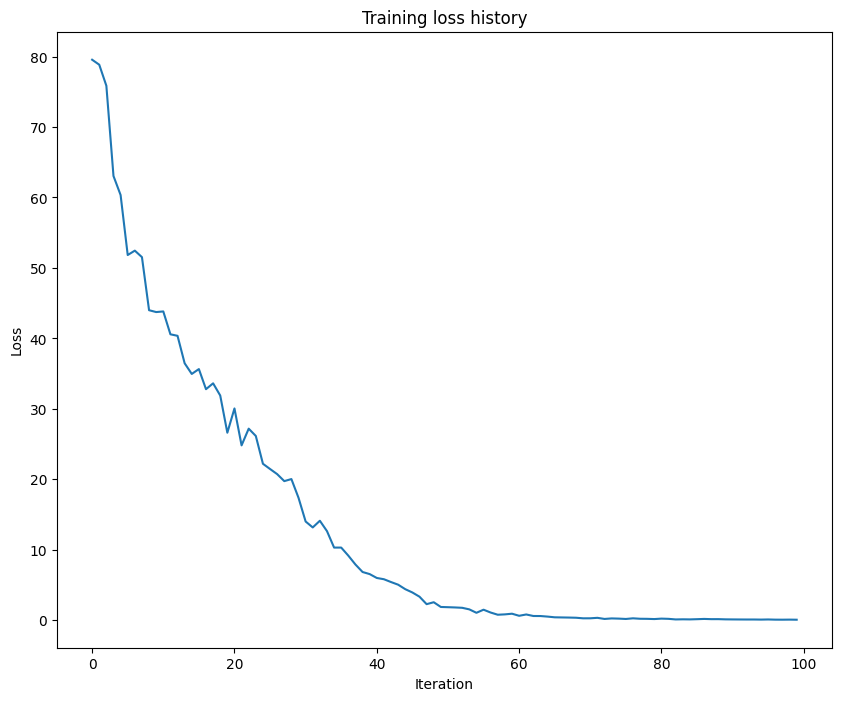

In [9]:
np.random.seed(231)

small_data = load_coco_data(max_train=50)

small_lstm_model = CaptioningRNN(
          cell_type='lstm',
          word_to_idx=data['word_to_idx'],
          input_dim=data['train_features'].shape[1],
          hidden_dim=512,
          wordvec_dim=256,
          dtype=np.float32,
        )

small_lstm_solver = CaptioningSolver(small_lstm_model, small_data,
           update_rule='adam',
           num_epochs=50,
           batch_size=25,
           optim_config={
             'learning_rate': 5e-3,
           },
           lr_decay=0.995,
           verbose=True, print_every=10,
         )

small_lstm_solver.train()

plt.plot(small_lstm_solver.loss_history)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Training loss history')
plt.show()

# LSTM 测试时间取样
修改在`CaptioningRNN`类中的`sample`方法去处理 `self.cell_type` 是 `lstm`的情况. 这应该只会用大概10行代码
完成后，从您的overfit LSTM模型中对一些训练集和验证集样本运行以下示例。

**第 10 块｜比较生成字幕与参考句**

**工作机制与执行链。** 每个样例从图像得到 h0，并从零 c 开始，逐词更新 h/c。显示时遇 END 截断文字，最多生成步数仍由采样函数限制。

在训练和验证样例上自回归解码，同时展示缓存的原图与参考句。虽然训练损失可能很低，验证图片上的描述仍可能错误；这正是小样本实验不能代替完整训练的原因。

前序输入：`small_data` 来自第 9 块，`data` 来自第 3 块，`small_lstm_model` 来自第 9 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `sample_coco_minibatch` | `split=split` | 决定使用训练划分或验证划分。 |
| `sample_coco_minibatch` | `batch_size=2` | 单次前向和更新使用的样本数；与训练集大小一起决定每轮的更新次数。 |
| `sample_coco_minibatch` | `data=small_data` | 包含训练与验证数据的字典。 |
| `decode_captions` | `captions=gt_captions` | 按时间排列的整数词编号矩阵。 |
| `decode_captions` | `captions=sample_captions` | 按时间排列的整数词编号矩阵。 |

**进入底层实现。**

- [`small_lstm_model.sample`](cs231n/classifiers/rnn.py#L117)：从图像特征初始化隐藏状态，从 START 开始，逐步嵌入上一预测词、更新 RNN/LSTM 状态并取最大词表得分。输出 token 数组，显示时再截断 END。


http://farm9.staticflickr.com/8175/8042929905_dbb7a3f616_z.jpg


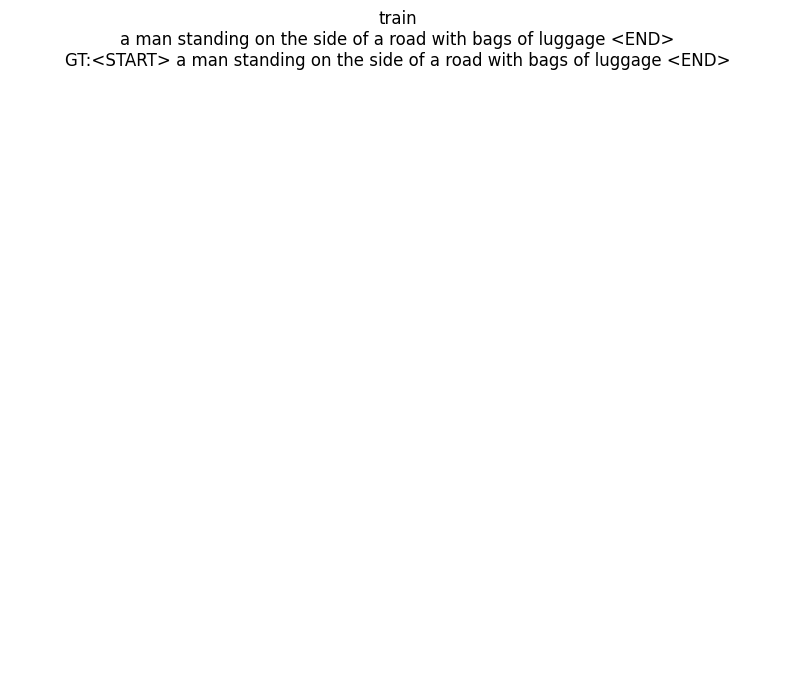

http://farm5.staticflickr.com/4134/4876982491_5359f44020_z.jpg


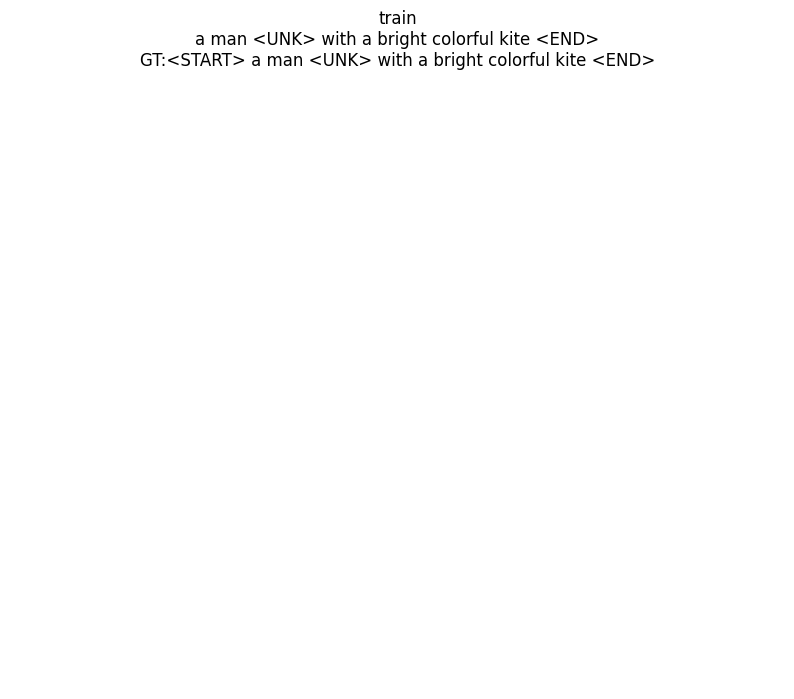

http://farm9.staticflickr.com/8318/8002651749_32511b0831_z.jpg


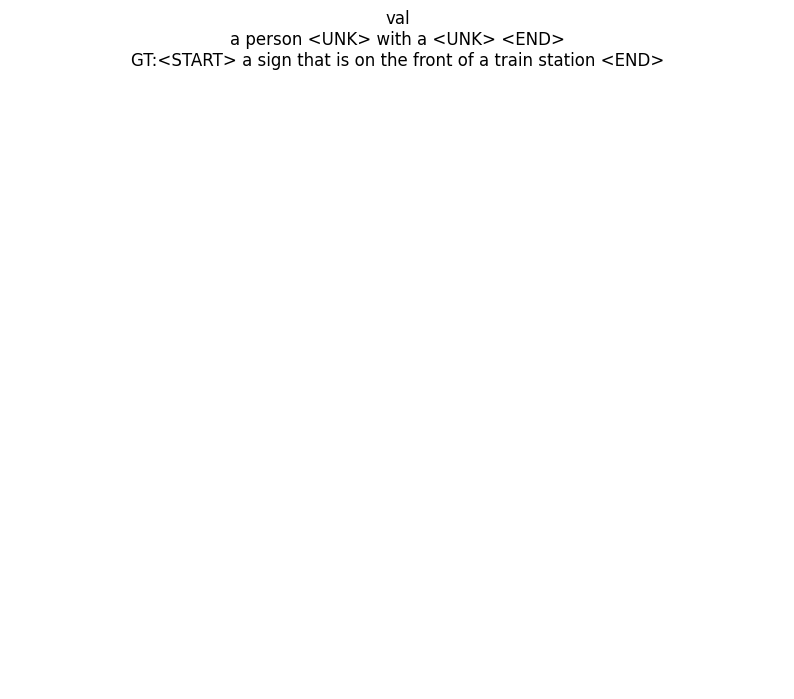

http://farm3.staticflickr.com/2605/3881233964_1808ff0a40_z.jpg


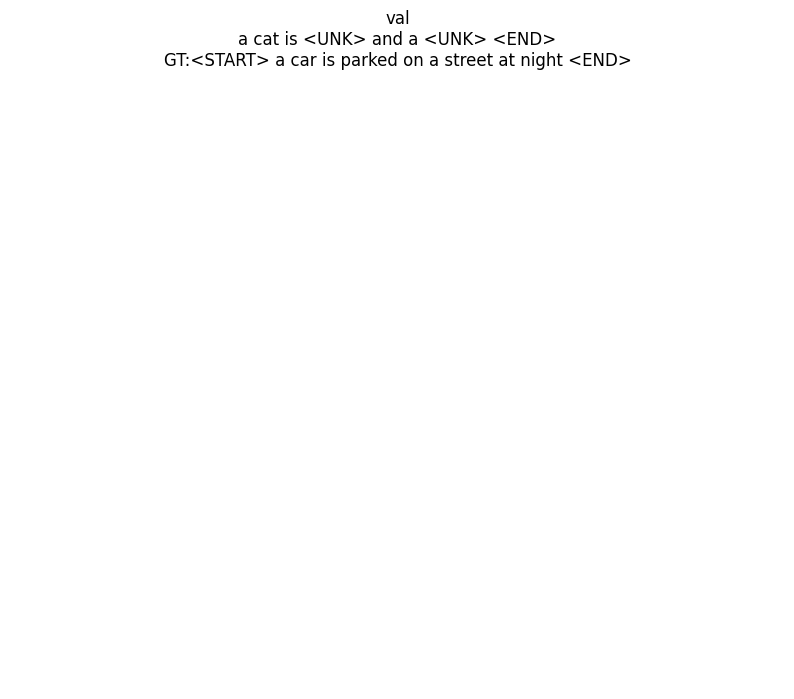

In [10]:
for split in ['train', 'val']:
    minibatch = sample_coco_minibatch(small_data, split=split, batch_size=2)
    gt_captions, features, urls = minibatch
    gt_captions = decode_captions(gt_captions, data['idx_to_word'])

    sample_captions = small_lstm_model.sample(features)
    sample_captions = decode_captions(sample_captions, data['idx_to_word'])

    for gt_caption, sample_caption, url in zip(gt_captions, sample_captions, urls):
        print(url)
        plt.title('%s\n%s\nGT:%s' % (split, sample_caption, gt_caption))
        plt.axis('off')
        plt.show()

# 额外学分:训练一个良好的字幕模式!
在对验证集抽样时，使用您在本例和前一篇笔记中实现的片段，尝试训练一个字幕模型，该模型可以提供适当的定性结果(比您在overfit模型中看到的随机垃圾更好)。我们只想看到验证集上的样本比随机的好。
除了通过检查结果对模型进行定性评估外，还可以使用BLEU unigram精度度量对模型进行定量评估。如果你能训练出一个能达到>0.3的BLEU unigram评分的模型，我们会给你一小笔额外的学分。BLEU分数范围从0到1;越接近1越好。如果您有兴趣了解更多关于BLEU的工作原理，可以参考[论文](http://www.aclweb.org/anthology/P02-1040.pdf)。
如果你想在GPU上训练得更快，可以使用PyTorch或TensorFlow。不过，您可以使用Numpy代码获得高于0.3的结果。我们提供给您的评估代码是与Numpy模型兼容，如上述定义…你应该能够适应它的TensorFlow/PyTorch，如果你走那条路线。

**第 11 块｜定义逐句 BLEU-1**

**工作机制与执行链。** 先去掉 START、END、UNK 等指定特殊 token，再用 unigram 权重计算逐句 BLEU。短句会受到 brevity penalty，简单词重合数不等于最终分数。

定义原题单参考句 BLEU-1：移除特殊 token，计算带 brevity penalty 的逐句 unigram BLEU，并对 1000 个抽样字幕求平均。它不是多参考 corpus BLEU-4，不能与采用其他协议的论文指标直接比较。

此处定义 `BLEU_score(gt_caption, sample_caption)`。函数体在调用时执行。

此处定义 `evaluate_model(model)`。函数体在调用时执行。

本块实际导入：`nltk`。各模块在本题中的职责见开头的库说明。

本块产出的变量接着用于：`evaluate_model` → 第 12 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `nltk.translate.bleu_score.sentence_bleu` | `weights=[1]` | 分别赋给各阶 n-gram 的权重，本题只用 unigram。 |
| `sample_coco_minibatch` | `split=split` | 决定使用训练划分或验证划分。 |
| `sample_coco_minibatch` | `batch_size=1000` | 单次前向和更新使用的样本数；与训练集大小一起决定每轮的更新次数。 |
| `sample_coco_minibatch` | `data=small_data` | 包含训练与验证数据的字典。 |
| `decode_captions` | `captions=gt_captions` | 按时间排列的整数词编号矩阵。 |
| `decode_captions` | `captions=sample_captions` | 按时间排列的整数词编号矩阵。 |

**进入底层实现。**

- [`model.sample`](cs231n/classifiers/rnn.py#L117)：从图像特征初始化隐藏状态，从 START 开始，逐步嵌入上一预测词、更新 RNN/LSTM 状态并取最大词表得分。输出 token 数组，显示时再截断 END。


In [11]:
import nltk
def BLEU_score(gt_caption, sample_caption):
    """接收一条参考字幕和一条生成字幕，去掉特殊 token，计算带长度惩罚的一元 BLEU。返回该句分数。"""
    reference = [x for x in gt_caption.split(' ') 
                 if ('<END>' not in x and '<START>' not in x and '<UNK>' not in x)]
    hypothesis = [x for x in sample_caption.split(' ') 
                  if ('<END>' not in x and '<START>' not in x and '<UNK>' not in x)]
    BLEUscore = nltk.translate.bleu_score.sentence_bleu([reference], hypothesis, weights = [1])
    return BLEUscore

def evaluate_model(model):
    """从原题的小数据对象分别抽取训练和验证字幕。由图像特征生成文本，计算并打印逐句 BLEU-1 的平均值。"""
    BLEUscores = {}
    for split in ['train', 'val']:
        minibatch = sample_coco_minibatch(small_data, split=split, batch_size=1000)
        gt_captions, features, urls = minibatch
        gt_captions = decode_captions(gt_captions, data['idx_to_word'])

        sample_captions = model.sample(features)
        sample_captions = decode_captions(sample_captions, data['idx_to_word'])

        total_score = 0.0
        for gt_caption, sample_caption, url in zip(gt_captions, sample_captions, urls):
            try:
                total_score += BLEU_score(gt_caption, sample_caption)
            except (IOError ,ZeroDivisionError) as x:
                print (x)

        BLEUscores[split] = total_score / len(sample_captions)

    for split in BLEUscores:
        print('Average BLEU score for %s: %f' % (split, BLEUscores[split]))

**第 12 块｜检查训练与验证字幕质量**

**工作机制与执行链。** 各抽 1000 条训练和验证字幕，分别解码、评分、求平均。训练抽样来自小数据，明显的训练验证差距说明过拟合。

评估刚训练的小样本 LSTM，分别报告训练与验证抽样的平均 BLEU-1。训练高分可能来自记忆；完整数据模型会在后面的独立 GPU 等价训练章节给出固定验证样本结果。

前序输入：`evaluate_model` 来自第 11 块，`small_lstm_model` 来自第 9 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `evaluate_model` | `model=small_lstm_model` | 当前待训练或评估的模型对象。 |

In [12]:
evaluate_model(small_lstm_model)

Average BLEU score for train: 1.000000
Average BLEU score for val: 0.176011


## 方法二：等价 GPU 后端与完整 COCO 训练

**工作机制与执行链。** 先在相同参数下验证 NumPy 与框架实现的前向、逐参数梯度、贪心解码和优化器更新。验证通过才读取完整课程划分。train_gpu 每轮无放回遍历 400135 条字幕，batch size 100 并保留最后 35 条，故每轮 4002 步、二十轮共 80040 步。已有完整检查点时只读取已完成记录，不把加载写成新训练。

上面的原 NumPy 前后向、梯度检查及 50 条字幕、50 轮训练保持独立。完整课程训练划分有 400,135 条字幕，使用 82,783 张图像的 512 维特征。原 CPU 路径的实测批次成本较高，因此完整数据训练采用下方经过对照验证的 GPU 实现；这是执行后端变更，不能将其结果写成 NumPy 后端的完整训练成绩。

**输入与数据流。** 图像特征通过同一仿射投影成为 h0；字幕去掉最后一个词后查表得到 256 维词向量；512 维循环层输出每个时间步的隐藏状态；共享词表投影得到 logits，与去掉 START 的目标字幕计算交叉熵。NULL 位置屏蔽，按字幕数而非有效词数归一化。

**参数对应。** PyTorch 的循环权重采用转置布局，LSTM 门序为 i/f/g/o，而原代码为 i/f/o/g，所以导入参数与对照梯度时必须换序。框架的第二组循环偏置固定为零，避免引入额外可训练自由度。课程 Adam 的时间步、偏差校正和 epsilon 位置也保持一致。验证同时覆盖 CPU/CUDA 前向、全部参数梯度、贪心解码及多步优化器更新。

**训练和输出。** 每轮无放回遍历全部训练字幕，batch size=100，保留尾批；Adam 学习率 5e-4，完整训练 20 轮，共 80,040 次更新。每轮在固定种子选出的 1,000 条验证字幕上评估损失和平均单句 BLEU-1，以验证损失选择最佳参数。检查点记录模型、优化器、数据排列、随机数和偏移位置。已有完成记录时载入并展示该实验，未完成时从检查点续训。

实现位于 [torch_captioning.py](cs231n/torch_captioning.py)，与原 [rnn.py](cs231n/classifiers/rnn.py) 分开维护。方法一不导入该模块也能独立运行。这里的 BLEU-1 是单参考句指标；同一图片的多条参考、corpus BLEU-4 等其他协议不可直接对比。

**第 13 块：顺着变量读**

本块实际导入：`cs231n.torch_captioning.verify_equivalence`、`cs231n.torch_captioning.train_gpu`。各模块在本题中的职责见开头的库说明。

本块产出的变量接着用于：`full_course_data` → 第 15 块，`gpu_lstm_history` → 第 14 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `load_coco_data` | `pca_features=True` | 是否读取课程 PCA 降维后的视觉特征。 |
| `train_gpu` | `data=full_course_data` | 包含训练与验证数据的字典。 |
| `train_gpu` | `cell_type='lstm'` | 选择普通 RNN 或 LSTM，决定时间步递推规则和门矩阵宽度。 |
| `verify_equivalence` | `device=device` | 张量或模型所在设备；同一运算的相关张量需兼容。 |

**进入底层实现。**

- [`train_gpu`](cs231n/torch_captioning.py#L157)：完整训练数据每轮无放回遍历，保存模型/优化器/RNG/排列/进度以恢复。
- [`verify_equivalence`](cs231n/torch_captioning.py#L108)：固定输入、权重、mask，检查损失、每个参数梯度和贪心解码。


**这里没有显式传入、但实际生效的默认参数。**

- `load_coco_data(..., base_dir=BASE_DIR)`：课程 COCO 文件所在目录，由共享路径配置解析。
- `load_coco_data(..., max_train=None)`：限制读取的训练字幕行数，不等于限制图像特征矩阵行数。
- `train_gpu(..., epochs=20)`：此次训练函数执行的轮数。
- `train_gpu(..., batch_size=100)`：单次前向和更新使用的样本数；与训练集大小一起决定每轮的更新次数。
- `train_gpu(..., seed=231)`：随机种子；数值梯度检查时用于重现相同掩码。

In [13]:
from cs231n.torch_captioning import verify_equivalence, train_gpu
# 先证明数据流和梯度一致，再执行/恢复完整训练。
backend_equivalence = {device: verify_equivalence(device) for device in ('cpu', 'cuda')}
print(backend_equivalence)
full_course_data = load_coco_data(pca_features=True)
gpu_lstm_model, gpu_lstm_report, gpu_lstm_history = train_gpu(full_course_data, 'lstm')
print(gpu_lstm_report)


{'cpu': {'rnn': {'loss_absolute_error': 0.0, 'gradient_max_absolute_errors': {'W_embed': 1.3877787807814457e-16, 'W_proj': 1.1102230246251565e-16, 'b_proj': 3.122502256758253e-17, 'W_vocab': 1.1102230246251565e-16, 'b_vocab': 1.1102230246251565e-16, 'Wx': 3.469446951953614e-18, 'Wh': 1.6653345369377348e-16, 'b': 1.3877787807814457e-16}, 'greedy_decoding_equal': True, 'adam_three_steps_equal': True, 'device': 'cpu'}, 'lstm': {'loss_absolute_error': 0.0, 'gradient_max_absolute_errors': {'W_embed': 2.7755575615628914e-17, 'W_proj': 4.163336342344337e-17, 'b_proj': 1.3877787807814457e-17, 'W_vocab': 2.3635607360183997e-17, 'b_vocab': 2.220446049250313e-16, 'Wx': 4.336808689942018e-19, 'Wh': 2.7755575615628914e-17, 'b': 5.551115123125783e-17}, 'greedy_decoding_equal': True, 'adam_three_steps_equal': True, 'device': 'cpu'}}, 'cuda': {'rnn': {'loss_absolute_error': 8.881784197001252e-16, 'gradient_max_absolute_errors': {'W_embed': 1.6653345369377348e-16, 'W_proj': 1.6653345369377348e-16, 'b_p

{'status': 'complete', 'backend': 'equivalent GPU; original NumPy full training not claimed', 'epochs_completed': 20, 'steps_completed': 80040, 'train_captions_per_epoch': 400135, 'best_epoch': 6, 'validation_loss': 24.980624961853028, 'validation_sentence_bleu1': 0.2816913090821388, 'validation_captions_evaluated': 1000, 'elapsed_seconds': 496.67522499999905, 'peak_gpu_memory_bytes': 425398784}


### 完整训练的曲线与字幕检查

**工作机制与执行链。** 每个 history 条目对应一个完整 epoch，横轴是轮数。左图展示每句验证损失，右图展示固定一千条验证字幕的平均单句 BLEU-1。二者优化方向与含义不同。随后打印同一已选模型的参考句和预测句，检查重复、UNK、物体混淆等不能从单个分数看出的错误。

使用逐轮保存的验证损失和 BLEU-1 绘制两幅独立曲线，再打印固定验证样本的参考句与生成句。检查模型是否过拟合以及是否生成重复、泛化或错误描述；保留不理想结果，不把低验证损失直接等同于高 BLEU。

**第 14 块：顺着变量读**

本块实际导入：`study_runtime.ROOT`。各模块在本题中的职责见开头的库说明。

前序输入：`gpu_lstm_history` 来自第 13 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `plt.subplots` | `figsize=(12, 4)` | 画布宽、高，以英寸计。 |
| `axes[0].plot` | `marker='o'` | 曲线上单个观测点的标记样式。 |
| `axes[0].set` | `xlabel='Epoch'` | 横轴标签，说明该轴的自变量。 |
| `axes[0].set` | `ylabel='Validation loss per caption'` | 纵轴标签，说明被观察的量。 |
| `axes[0].set` | `title='LSTM full COCO'` | 图的标题。 |
| `axes[1].plot` | `marker='s'` | 曲线上单个观测点的标记样式。 |
| `axes[1].set` | `xlabel='Epoch'` | 横轴标签，说明该轴的自变量。 |
| `axes[1].set` | `ylabel='Mean sentence BLEU-1'` | 纵轴标签，说明被观察的量。 |
| `axes[1].set` | `title='Fixed 1000 validation captions'` | 图的标题。 |
| `(project_root / 'outputs' / 'full_coco_lstm_gpu_equivalent' / 'caption_examples.json').read_text` | `encoding='utf-8'` | 读取或写入文本所采用的字符编码。 |

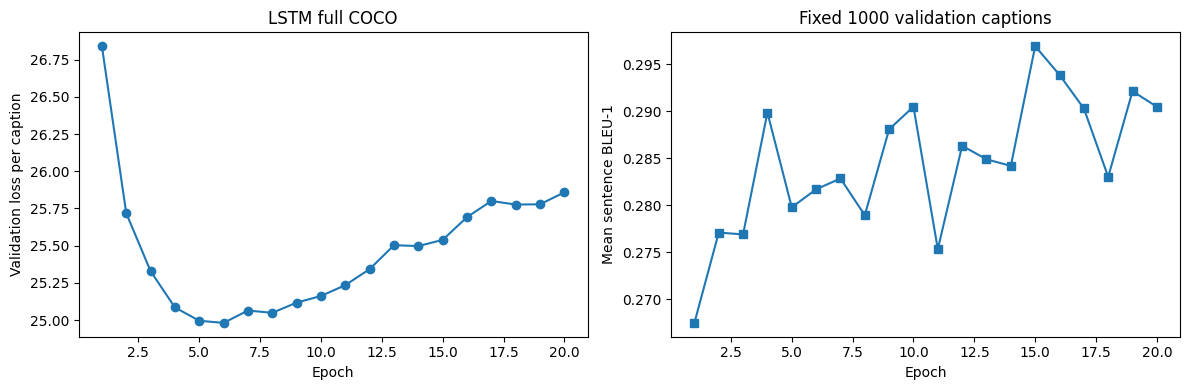

Reference: <START> the two men are <UNK> for control of the soccer ball <END>
Generated: a couple of people that are on a horse <END>
BLEU-1: 0.1989
Reference: <START> several people walking on a platform next to a train <END>
Generated: a train on a track near a <UNK> <END>
BLEU-1: 0.3723
Reference: <START> a baby horse has its <UNK> under a big horse <END>
Generated: a brown and black dog is looking at a cow <END>
BLEU-1: 0.2
Reference: <START> a large clock <UNK> the <UNK> side of a building <END>
Generated: a clock is shown on the top of a building <END>
BLEU-1: 0.6
Reference: <START> an elephant standing on a lush green field <END>
Generated: a <UNK> elephant is <UNK> its <UNK> in the <UNK> <END>
BLEU-1: 0.2388
Reference: <START> a woman that has <UNK> <UNK> next to a man wearing a <UNK> <END>
Generated: a man sitting on a couch with a laptop computer <END>
BLEU-1: 0.4
Reference: <START> a plate of food with a <UNK> <UNK> and colorful vegetables <END>
Generated: a plate with a pie

In [14]:
# 输入为每轮真实验证记录，输出损失和 BLEU 曲线；两个纵轴分开显示。
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = [row['epoch'] for row in gpu_lstm_history]
axes[0].plot(epochs, [row['validation_loss'] for row in gpu_lstm_history], marker='o')
axes[0].set(xlabel='Epoch', ylabel='Validation loss per caption', title='LSTM full COCO')
axes[1].plot(epochs, [row['validation_sentence_bleu1'] for row in gpu_lstm_history], marker='s')
axes[1].set(xlabel='Epoch', ylabel='Mean sentence BLEU-1', title='Fixed 1000 validation captions')
plt.tight_layout()
plt.show()
from study_runtime import ROOT as project_root
examples = json.loads((project_root / 'outputs' / 'full_coco_lstm_gpu_equivalent' / 'caption_examples.json').read_text(encoding='utf-8'))
for example in examples[:10]:
    print('Reference:', example['reference'])
    print('Generated:', example['prediction'])
    print('BLEU-1:', round(example['bleu1'], 4))


### 方法二的解码改进：长度归一化束搜索

**工作机制与执行链。** 冻结验证损失选定的权重。每一步从“当前 beam × 词表”候选中选 top-k，同时按父 beam 索引重排词序列、累计 log 概率和循环状态；LSTM 的 h、c 都要重排。先用宽度一验证与贪心文本一致，再在开发子集选宽度和长度系数，最后在图像不重叠的确认子集检查收益。没有增加训练步数。

贪心解码只保留每一步概率最高的一个词，无法比较多个完整句子的累积得分。这里冻结已经训练完成的模型权重，同时保留多个候选句：候选得分为累计 log 概率除以生成长度的 alpha 次方，每步保留得分最高的 k 条。长度不含 START，首次 END 计入长度；已结束候选只能继续 END，且不再增加长度或改变累计概率。没有屏蔽 UNK，也没有改变评估时的文本清洗规则。

**输入与状态。** 输入为一批图像特征和冻结模型。每个 beam 都有自己的词序列、累计得分、长度、完成标记，以及 RNN 的 h 或 LSTM 的 h/c。每步 top-k 选择后，这些对象必须按同一个父候选索引重排；只更新 token 而不重排循环状态会产生错误的条件概率。输出是每张图得分最高的 token 序列，再按原规则转成文字。

**如何选择和确认。** 先检查宽度 1、alpha=0 的文本与原贪心完全一致，再在原固定 1000 条验证字幕上比较贪心以及宽度 3/5、alpha 0/0.6/1.0 的组合。依据该开发子集的 BLEU-1 选方案，然后从其余验证图像中抽取另一组 1000 条字幕复核，两组图像集合不重叠。确认集不用于挑选束宽或长度系数，避免把同一子集的调参收益当作泛化保证。

该方法不增加训练更新，模型、数据和 BLEU 定义保持不变，新增成本是推理搜索。结果包含开发与确认指标、逐句改善比例和耗时；如果候选没有超过贪心，就保留原选择，不强行声称改进。实现见 [beam_search.py](cs231n/beam_search.py)。

**第 15 块：顺着变量读**

本块实际导入：`cs231n.beam_search.compare_decoding`。各模块在本题中的职责见开头的库说明。

前序输入：`full_course_data` 来自第 13 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `compare_decoding` | `data=full_course_data` | 包含训练与验证数据的字典。 |
| `compare_decoding` | `cell_type='lstm'` | 选择普通 RNN 或 LSTM，决定时间步递推规则和门矩阵宽度。 |
| `json.dumps` | `ensure_ascii=False` | JSON 中非 ASCII 字符是否写成转义序列。 |
| `json.dumps` | `indent=2` | JSON 输出缩进宽度，只改变记录的可读性。 |

**进入底层实现。**

- [`compare_decoding`](cs231n/beam_search.py#L73)：选参只用原 1000 验证字幕，另取图像不重叠的 1000 字幕作确认。


In [15]:
from cs231n.beam_search import compare_decoding
beam_lstm_report = compare_decoding(full_course_data, 'lstm')
assert beam_lstm_report['width1_matches_greedy']
assert beam_lstm_report['image_sets_disjoint']
print(json.dumps(beam_lstm_report, ensure_ascii=False, indent=2))


{"width": 0, "length_alpha": 0, "development_bleu1": 0.2816913090821388, "seconds": 0.11955060000764206}


{"width": 3, "length_alpha": 0, "development_bleu1": 0.30371951118486, "seconds": 0.16221219999715686}


{"width": 3, "length_alpha": 0.6, "development_bleu1": 0.3060718264782603, "seconds": 0.1639864999888232}


{"width": 3, "length_alpha": 1.0, "development_bleu1": 0.30673000107449755, "seconds": 0.14543610000691842}


{"width": 5, "length_alpha": 0, "development_bleu1": 0.30115515158666506, "seconds": 0.1841007999901194}

{"width": 5, "length_alpha": 0.6, "development_bleu1": 0.29861973964502075, "seconds": 0.18395439999585506}

{"width": 5, "length_alpha": 1.0, "development_bleu1": 0.299673765672104, "seconds": 0.19160079999710433}

{"cell_type": "lstm", "model_checkpoint_epoch": 6, "selection": "maximum development mean sentence BLEU-1; confirmation not used for selection", "development_captions": 1000, "confirmation_captions": 1000, "image_sets_disjoint": true, "width1_matches_greedy": true, "candidates": [{"width": 0, "length_alpha": 0, "development_bleu1": 0.2816913090821388, "seconds": 0.11955060000764206}, {"width": 3, "length_alpha": 0, "development_bleu1": 0.30371951118486, "seconds": 0.16221219999715686}, {"width": 3, "length_alpha": 0.6, "development_bleu1": 0.3060718264782603, "seconds": 0.1639864999888232}, {"width": 3, "length_alpha": 1.0, "development_bleu1": 0.30673000107449755, "seconds": 0.14543610000691842}, {"width": 5, "length_alpha": 0, "development_bleu1": 0.30115515158666506, "seconds": 0.1841007999901194}, {"width": 5, "length_alpha": 0.6, "development_bleu1": 0.29861973964502075, "seconds": 0.18395439999585506}, {"width": 5, "length_alpha": 1.0, "development_bleu1": 0.299673765672104, "sec

{
  "cell_type": "lstm",
  "model_checkpoint_epoch": 6,
  "selection": "maximum development mean sentence BLEU-1; confirmation not used for selection",
  "development_captions": 1000,
  "confirmation_captions": 1000,
  "image_sets_disjoint": true,
  "width1_matches_greedy": true,
  "candidates": [
    {
      "width": 0,
      "length_alpha": 0,
      "development_bleu1": 0.2816913090821388,
      "seconds": 0.11955060000764206
    },
    {
      "width": 3,
      "length_alpha": 0,
      "development_bleu1": 0.30371951118486,
      "seconds": 0.16221219999715686
    },
    {
      "width": 3,
      "length_alpha": 0.6,
      "development_bleu1": 0.3060718264782603,
      "seconds": 0.1639864999888232
    },
    {
      "width": 3,
      "length_alpha": 1.0,
      "development_bleu1": 0.30673000107449755,
      "seconds": 0.14543610000691842
    },
    {
      "width": 5,
      "length_alpha": 0,
      "development_bleu1": 0.30115515158666506,
      "seconds": 0.1841007999901194
    },

### 保存本次实验
输入是上面实际训练得到的模型、指标和曲线。只保存模型参数与实验结果，不复制原始数据；输出写入本题独立目录，供运行验证核对。

**工作机制与执行链。** globals() 提供当前 notebook 的命名空间。save_experiment 按约定变量名读取已经算出的标量、曲线和模型，把它们写到本题独立输出目录。这里没有前向、反向或新的参数更新；没有适用标量的题，数值检查和图像仍保存在前面的单元输出。

**第 16 块：顺着变量读**

本块实际导入：`study_runtime.save_experiment`。各模块在本题中的职责见开头的库说明。

In [16]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '012_LSTM_Captioning')


本机实验指标： {}


## 实践补充：问题、检查与方法选择

**数据流要点。** LSTM 反向同时包含 h 和 c 两条跨时间路径；门序换错会造成前向和梯度同时错误。GPU 映射中显式交换 o/g，并冻结额外循环偏置。

**本次结果。** 完整训练后 LSTM 验证损失低于 RNN，但固定验证字幕的 BLEU-1 没有更高，说明两个指标并不等价。未达到 0.3 加分参考也照实保留。

**改进评估。** 下方在冻结权重上比较束搜索，用另一组图像不重叠的字幕确认结果。解码收益与新增训练收益分开，不把搜索耗时隐藏掉。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。